# Seasonal skill by climate type

CFE streamflow forced with AORC, MRMS Pass 2 and MRMS radar-only, evaluated at 818 USGS gages.

This notebook reads the tables written by the five evaluation steps (`results/tables`, see the README) and draws box plots of each metric by **climate type** (aridity zone) and **season**, one panel per rain product.

How to read every figure: one box is the distribution over gages. The box spans the quartiles, the line inside is the median, the dashed whiskers reach the most extreme value within 1.5 box heights of the box. Values beyond the whiskers are not drawn. A box needs at least 5 gages.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))        # the repository root
from cfe_eval import common as cm
from cfe_eval import config as cfg
from cfe_eval import plots

%matplotlib inline
plots.slide_style()
cfg.FIGURES.mkdir(parents=True, exist_ok=True)
print("tables :", cfg.TABLES)
print("figures:", cfg.FIGURES)

tables : /home/claude/cfe_evel/results/tables
figures: /home/claude/cfe_evel/results/figures


## Settings

`EVENT_SET` chooses the events behind the event figures: `"all"` (every detected event) or `"larger"` (about 3 floods per year at each gage). With `"larger"` a gage has only a few events per season, so the seasonal boxes of single gages become coarse; the pooled table in section 4 is the better view for the larger floods.

In [2]:
EVENT_SET = "all"
WHISKERS = 1.5      # 1.5 box heights; use (5, 95) for the 5th and 95th percentiles
SAVE = True          # write every figure to results/figures as PNG, 300 dpi

def save(fig, name):
    if SAVE:
        fig.savefig(cfg.FIGURES / f"{name}.png")

## 1. Tables and gages

In [3]:
gages = cm.read_table("gages")
cont = cm.read_table("continuous_metrics")
ctg = cm.read_table("contingency")
ems = cm.read_table("event_metrics_site")
log = cm.read_table("run_log")
print(log.groupby(["step", "status"]).size().to_string())

counts = (gages.groupby(["aridity_zone", "area_class"]).size().unstack(fill_value=0)
          .reindex(index=cfg.ZONES, columns=cfg.AREA_LABELS))
counts["all"] = counts.sum(axis=1)
counts.loc["all"] = counts.sum()
counts.rename_axis(index="climate type", columns="drainage area (km2)")

step              status
02_continuous     ok        818
03_events         ok        818
04_event_metrics  ok        818


drainage area (km2),<100,100-500,500-1000,all
climate type,,,,
Arid,7,12,3,22
Semi-arid,9,16,10,35
Semi-humid,3,22,19,44
Humid,192,336,189,717
all,211,386,221,818


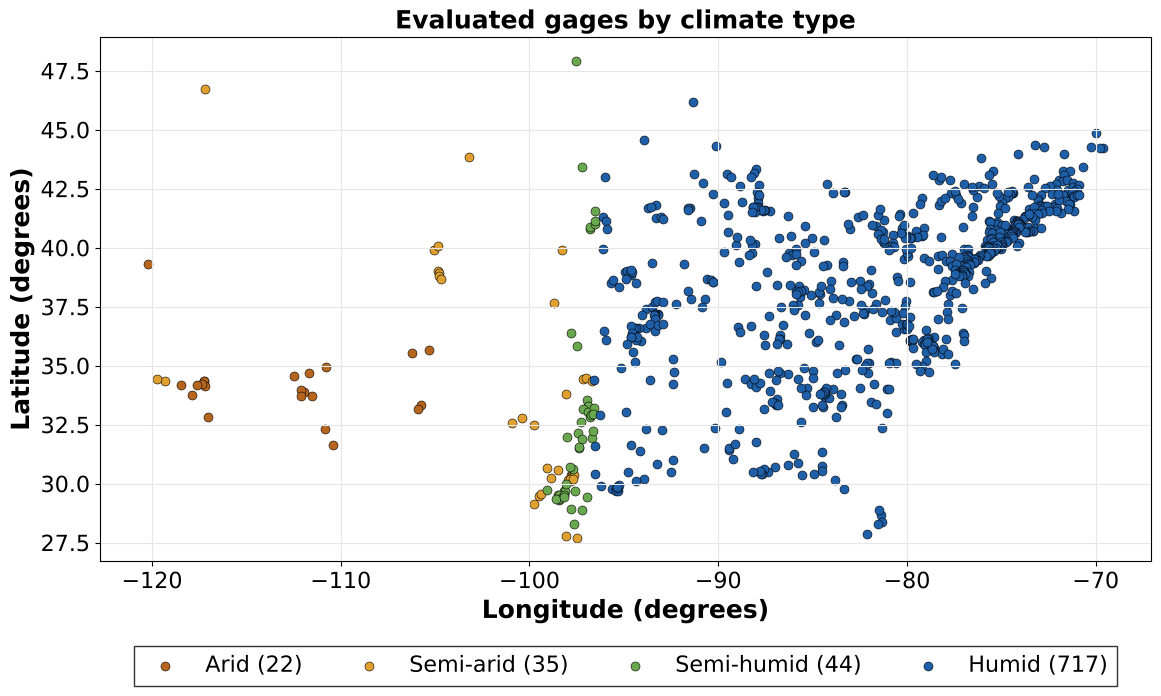

In [4]:
zone_colors = {"Arid": "#b5651d", "Semi-arid": "#e0a030", "Semi-humid": "#6aa84f", "Humid": "#1f5fa8"}
fig, ax = plt.subplots(figsize=(13.33, 7))
for z in cfg.ZONES:
    g = gages[gages["aridity_zone"] == z]
    ax.scatter(g["lon"], g["lat"], s=42, color=zone_colors[z], edgecolor="black", linewidth=0.4,
               label=f"{z} ({len(g)})")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_aspect(1.25)
ax.grid(color="0.9")
ax.set_title("Evaluated gages by climate type")
ax.legend(frameon=True, edgecolor="black", fancybox=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
fig.tight_layout()
save(fig, "gages_by_climate_type")

The gages are not spread evenly over the climate types: most are in the humid East. Keep the number of gages in mind when comparing boxes (the single-product figures print it under each climate type).

## 2. Long-term series metrics

Seasonal values use all hours of that season in the scoring window (Oct 2021 to Dec 2025), every year pooled, for each gage.

### Percent bias (PB)

PB = sum(sim - obs) / sum(obs) x 100. Positive = the model gives too much flow.

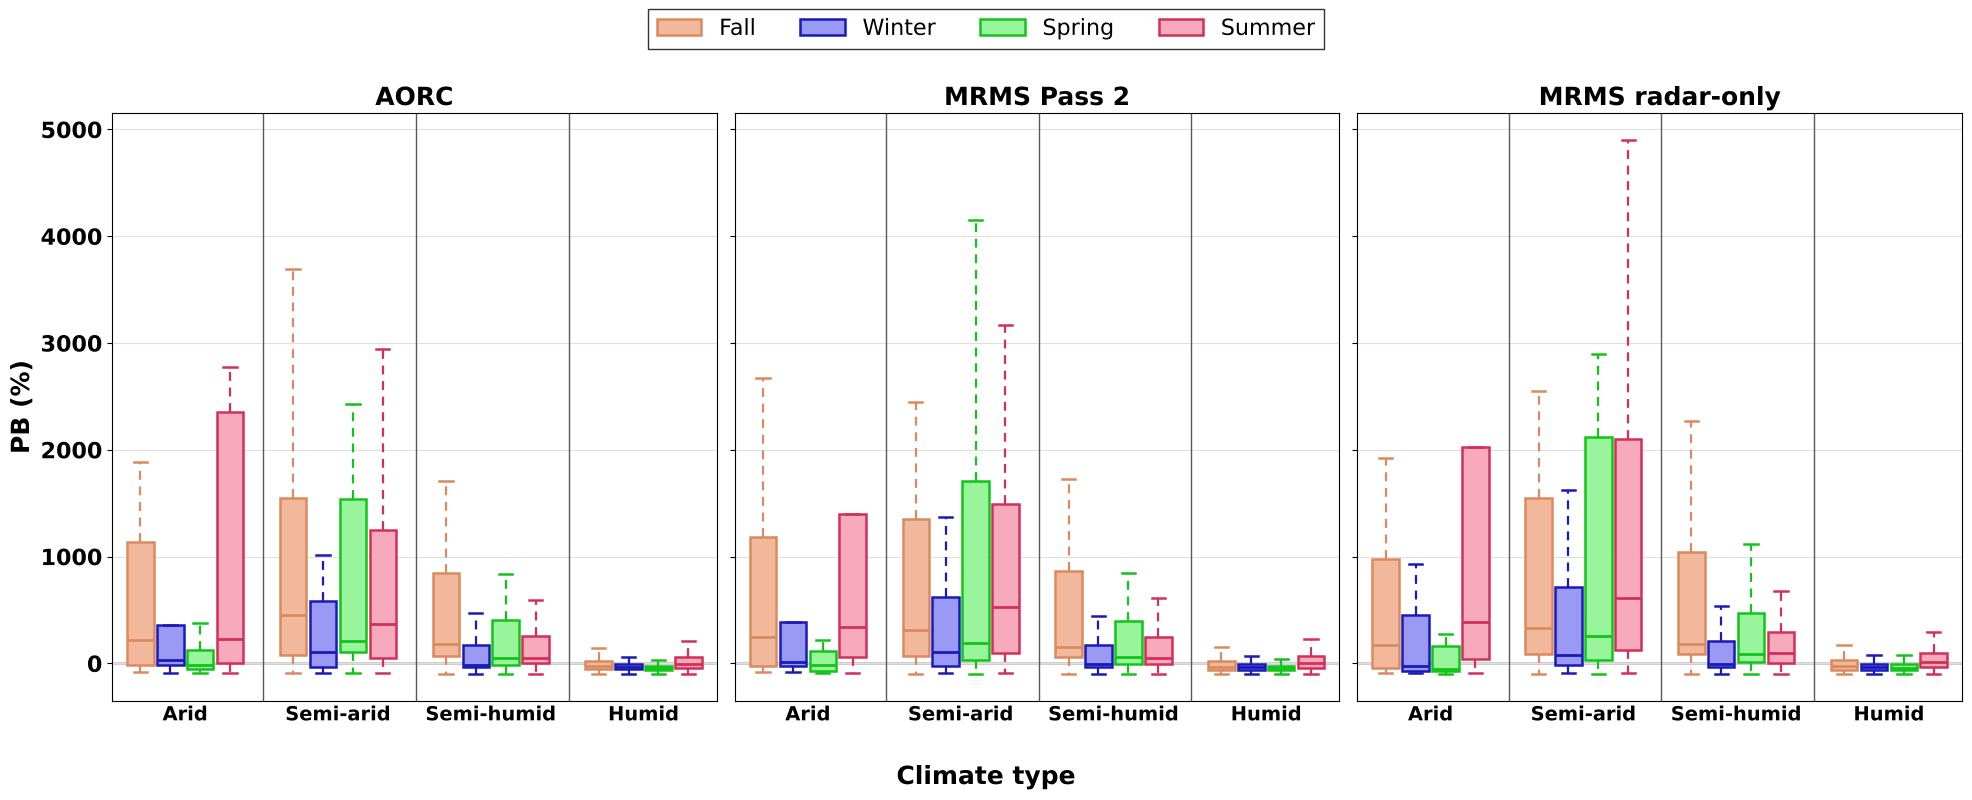

In [5]:
seas = cont[cont["period_type"] == "season"].rename(columns={"period": "season"})

fig = plots.figure_by_product(seas, "PBIAS_pct", "PB (%)", ref=0, whis=WHISKERS)
save(fig, "PB_by_climate_season")

The dry climate types stretch the axis, so the humid boxes are hard to read. The next figure shows the same data on an axis that is linear between -100 and +100 % and logarithmic above.

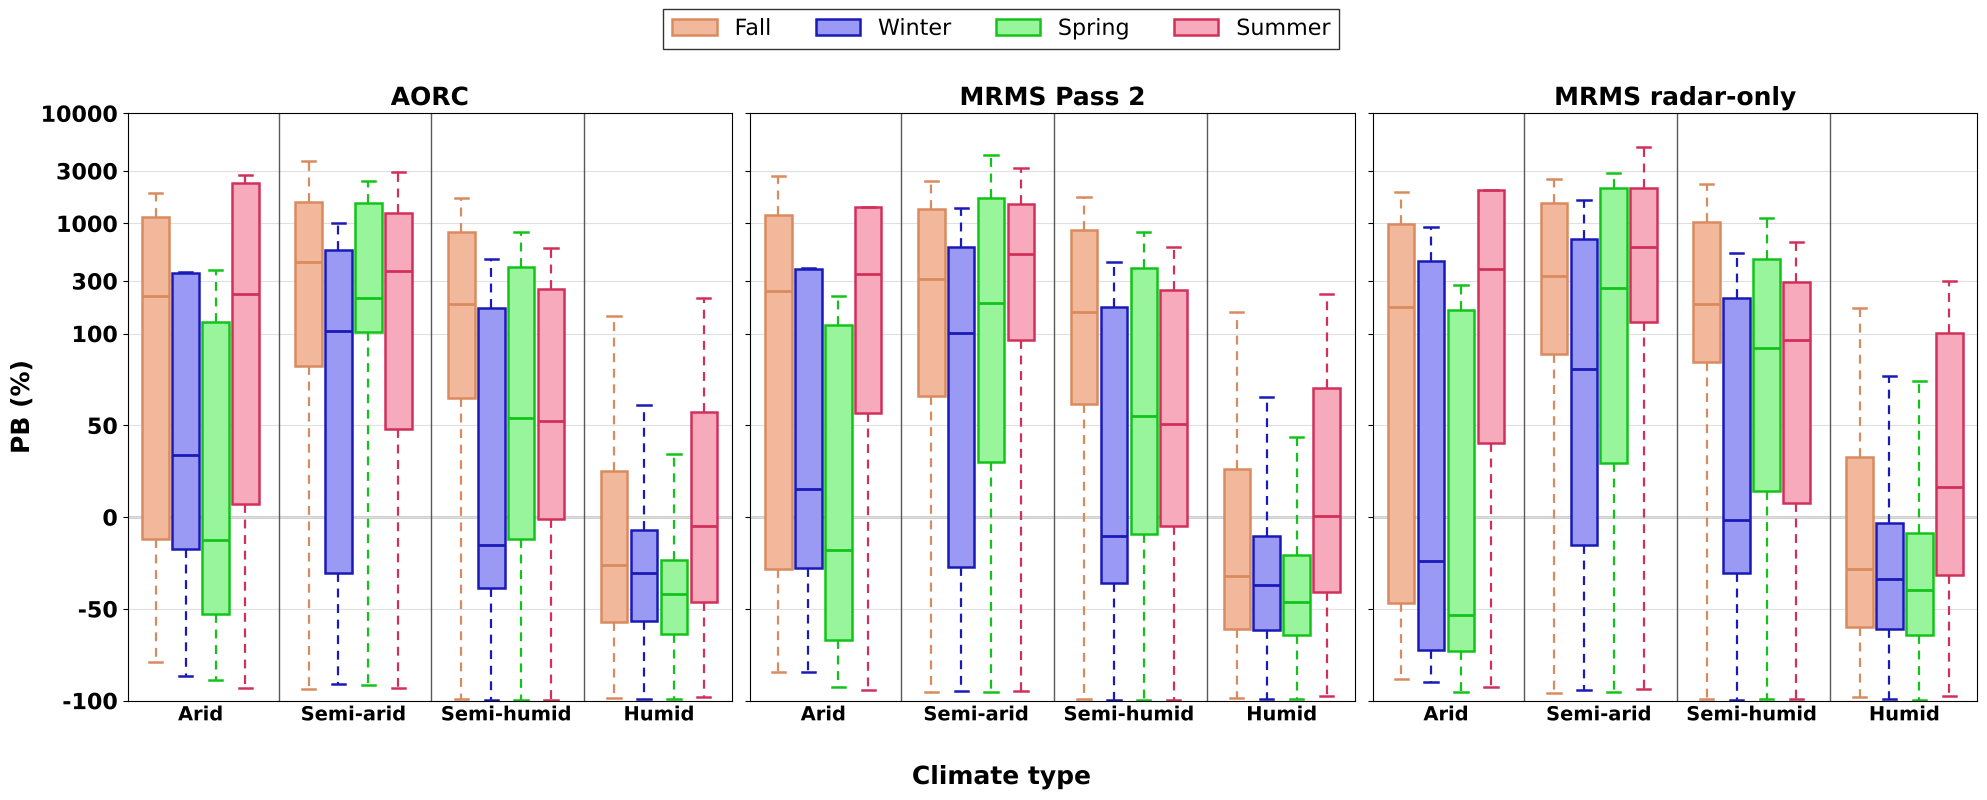

In [6]:
fig = plots.figure_by_product(seas, "PBIAS_pct", "PB (%)", ref=0, whis=WHISKERS)
for ax in fig.axes:
    ax.set_yscale("symlog", linthresh=100, linscale=1.5)
    ax.set_yticks([-100, -50, 0, 50, 100, 300, 1000, 3000, 10000])
    ax.set_yticklabels(["-100", "-50", "0", "50", "100", "300", "1000", "3000", "10000"])
    ax.minorticks_off()
    ax.set_ylim(-100, None)
save(fig, "PB_by_climate_season_symlog")

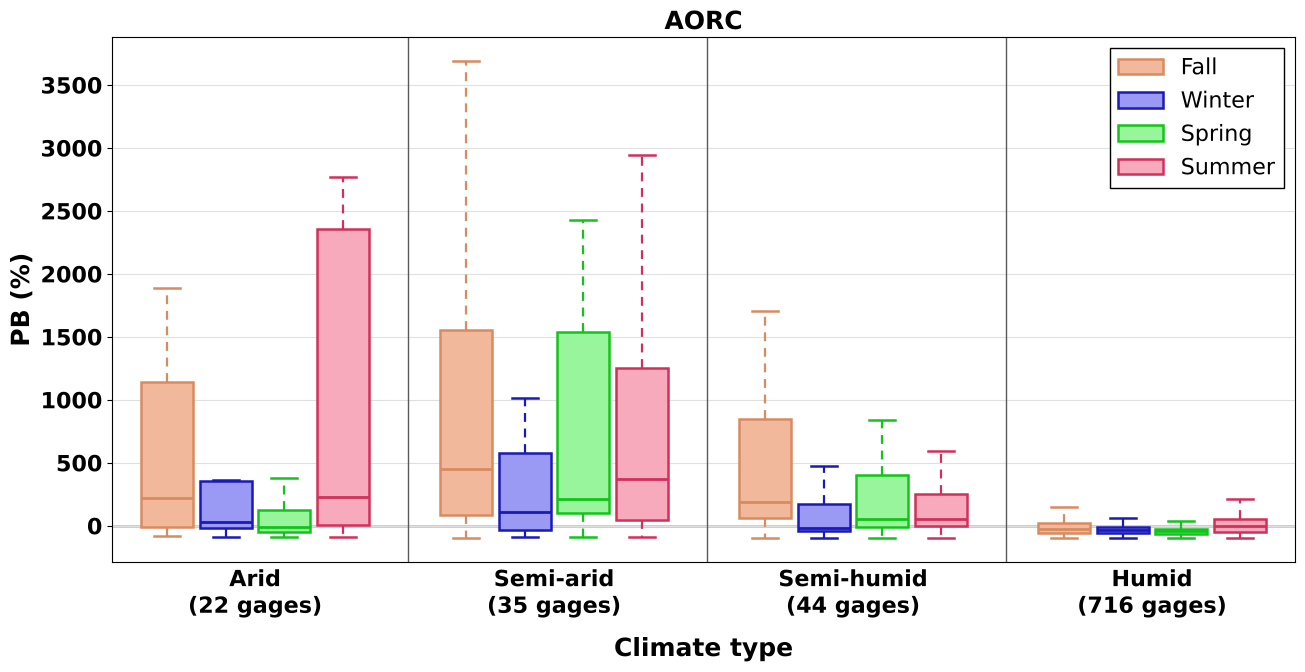

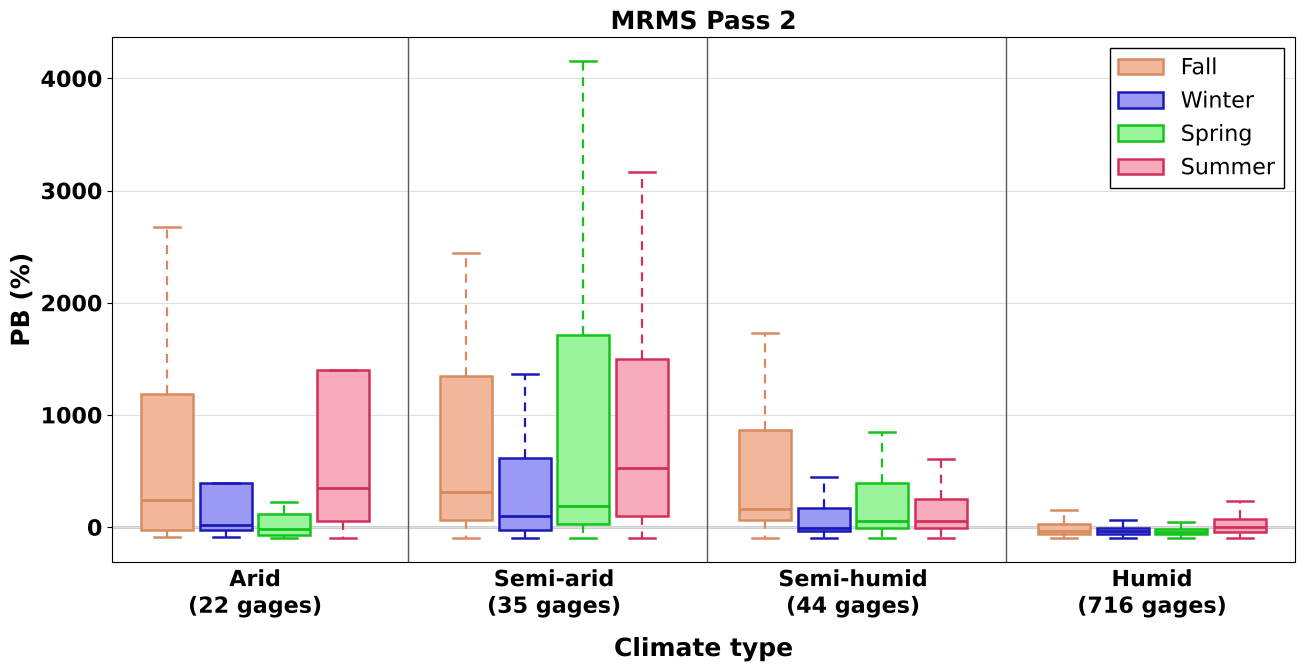

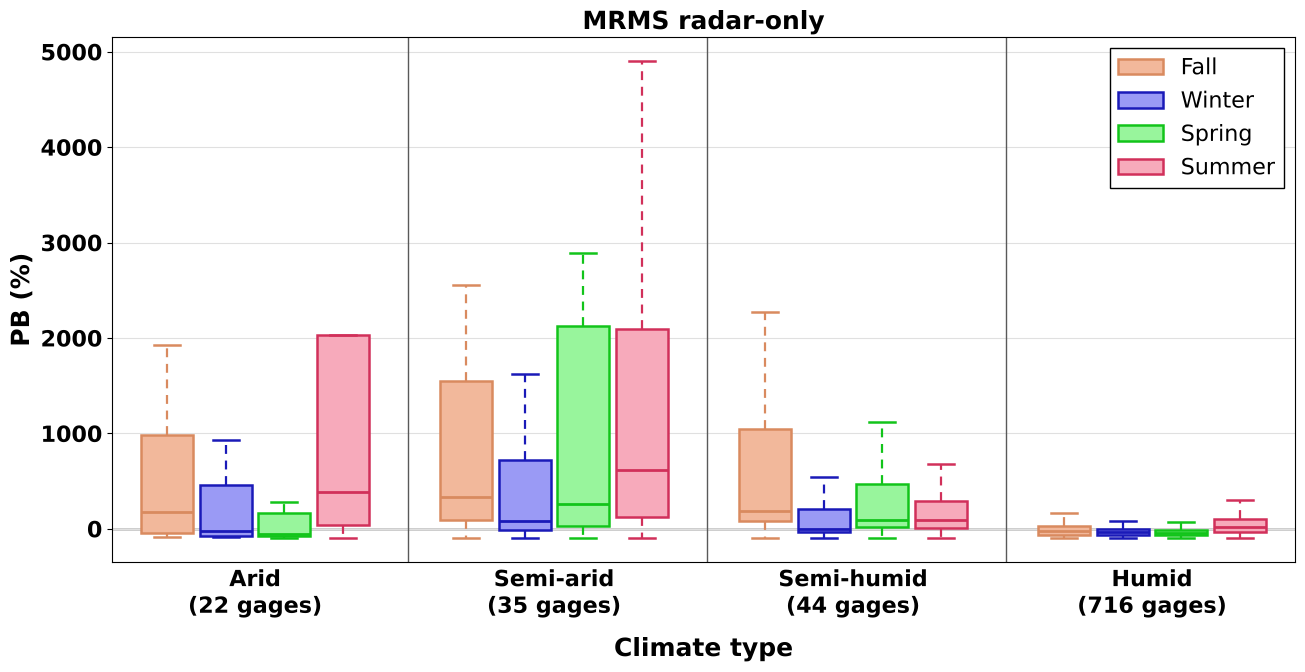

In [7]:
for prod in cfg.PRODUCTS:
    fig = plots.figure_single(seas, "PBIAS_pct", "PB (%)", prod, ref=0, whis=WHISKERS)
    save(fig, f"PB_by_climate_season_{prod}")

### Normalized Nash-Sutcliffe efficiency (NNSE)

NNSE = 1 / (2 - NSE). 1 = perfect, 0.5 = as good as the observed mean, below 0.5 = worse than the mean.

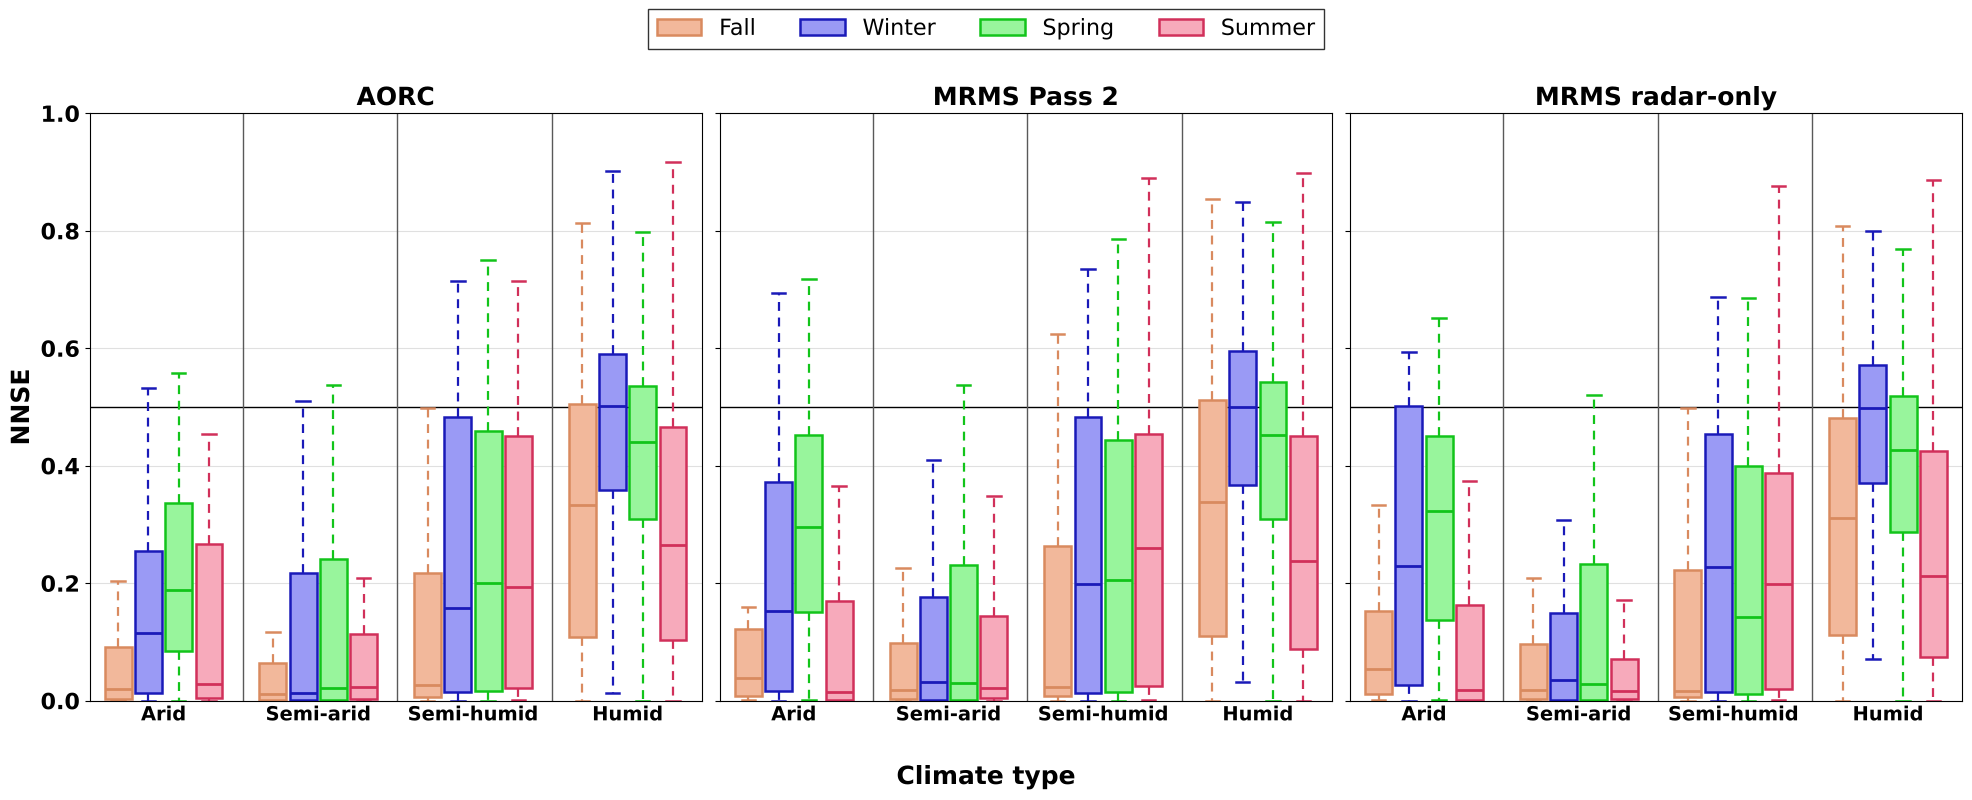

In [8]:
fig = plots.figure_by_product(seas, "NNSE", "NNSE", ref=0.5, whis=WHISKERS, ylim=(0, 1))
save(fig, "NNSE_by_climate_season")

### Normalized RMSE (NRMSE)

NRMSE = RMSE / mean observed flow x 100. The axis is logarithmic because the values span two orders of magnitude between climate types.

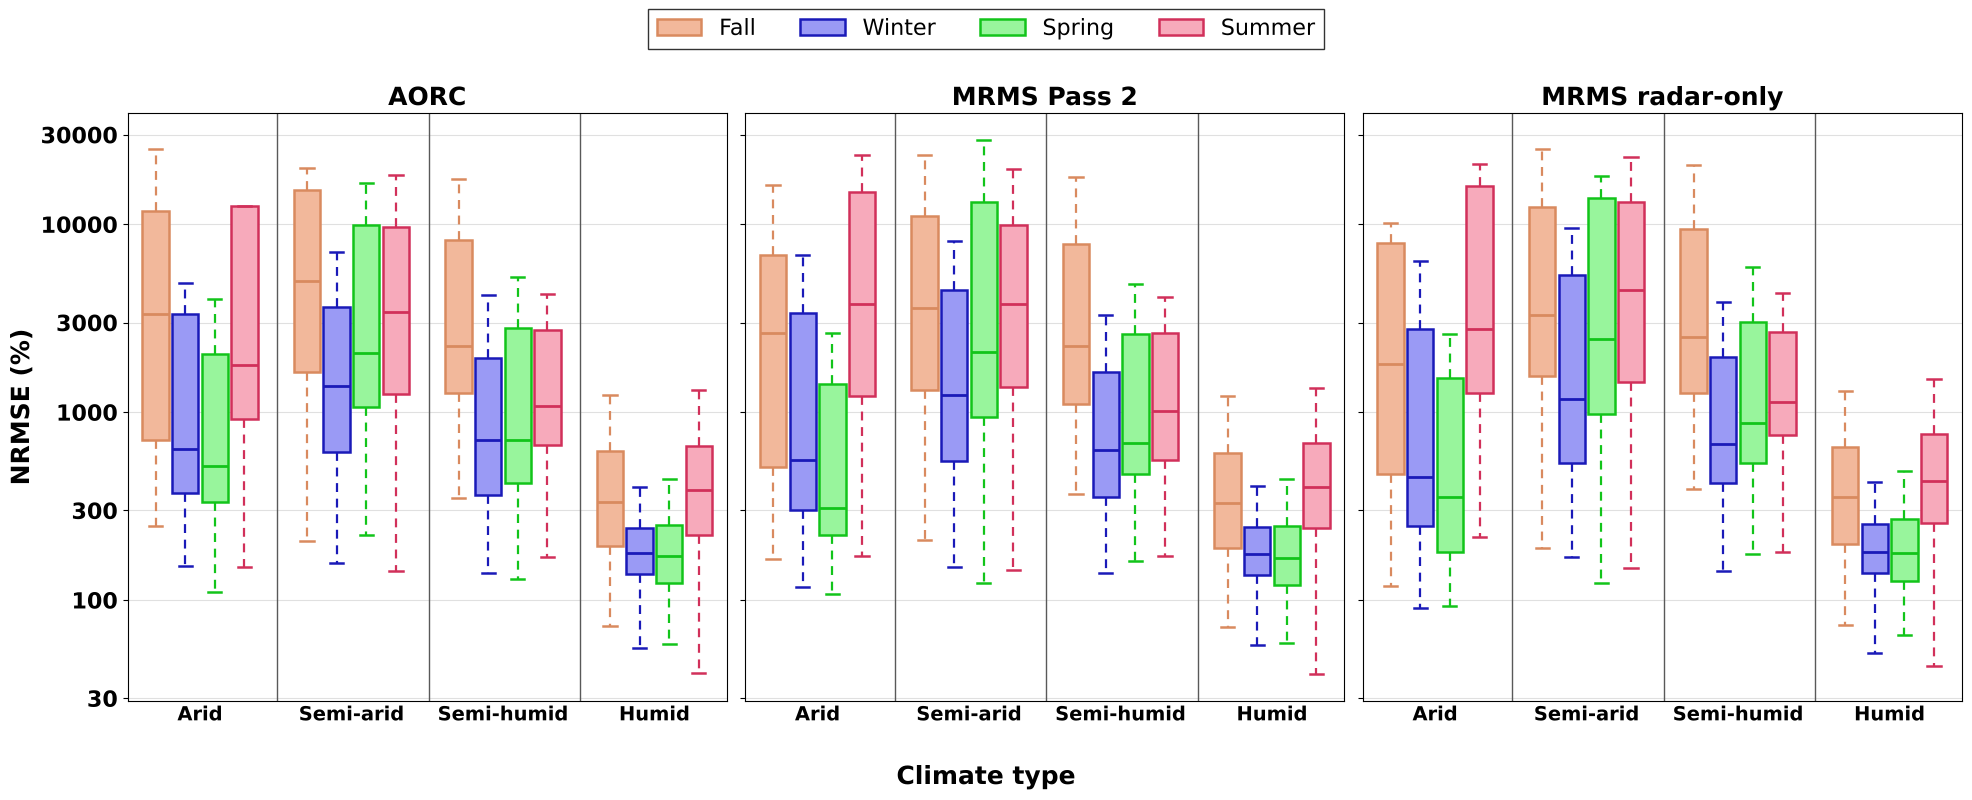

In [9]:
fig = plots.figure_by_product(seas, "NRMSE_pct", "NRMSE (%)", whis=WHISKERS)
for ax in fig.axes:
    ax.set_yscale("log")
    ax.set_yticks([30, 100, 300, 1000, 3000, 10000, 30000])
    ax.set_yticklabels(["30", "100", "300", "1000", "3000", "10000", "30000"])
    ax.minorticks_off()
save(fig, "NRMSE_by_climate_season")

### Medians behind the three figures

In [10]:
med = (seas.groupby(["product", "aridity_zone", "season"])[["PBIAS_pct", "NNSE", "NRMSE_pct"]].median()
       .round(2).unstack("season").reindex(columns=cfg.SEASONS, level=1)
       .reindex(index=[(p, z) for p in cfg.PRODUCTS for z in cfg.ZONES]))
med.to_csv(cfg.FIGURES / "medians_continuous_by_climate_season.csv")
med

PBIAS_pct                          NNSE                \
season                    Fall  Winter  Spring  Summer  Fall Winter Spring   
product aridity_zone                                                         
AORC    Arid            219.65   33.59  -12.42  226.49  0.02   0.12   0.19   
        Semi-arid       449.78  105.51  210.55  371.52  0.01   0.01   0.02   
        Semi-humid      185.09  -15.28   54.27   52.21  0.03   0.16   0.20   
        Humid           -25.97  -30.18  -41.91   -4.69  0.33   0.50   0.44   
MRMS_P2 Arid            243.03   15.17  -17.71  344.59  0.04   0.15   0.29   
        Semi-arid       315.31  102.20  188.93  530.57  0.02   0.03   0.03   
        Semi-humid      157.02  -10.24   55.10   50.86  0.02   0.20   0.21   
        Humid           -31.87  -37.23  -46.08    0.63  0.34   0.50   0.45   
MRMS_RO Arid            175.37  -23.88  -53.22  385.54  0.05   0.23   0.32   
        Semi-arid       331.08   80.62  259.39  615.76  0.02   0.04   0.03   
        Semi-humid      186.05   -1.74   91.97   96.37  0.02   0.23   0.14   
        Humid           -28.16  -33.60  -39.81   16.28  0.31   0.50   0.43   

                            NRMSE_pct                             
season               Summer      Fall   Winter   Spring   Summer  
product aridity_zone                                              
AORC    Arid           0.03   3329.76   636.98   517.41  1777.31  
        Semi-arid      0.02   4969.33  1376.36  2061.77  3432.67  
        Semi-humid     0.19   2245.89   714.58   710.29  1074.45  
        Humid          0.27    333.32   177.95   172.39   385.05  
MRMS_P2 Arid           0.01   2651.52   554.59   310.03  3749.50  
        Semi-arid      0.02   3602.59  1233.73  2082.65  3750.24  
        Semi-humid     0.26   2238.10   629.73   682.90  1015.50  
        Humid          0.24    327.39   176.68   166.98   398.00  
MRMS_RO Arid           0.02   1799.73   451.79   352.45  2755.40  
        Semi-arid      0.02   3276.78  1182.27  2455.47  4456.32  
        Semi-humid     0.20   2499.25   673.60   874.79  1132.55  
        Humid          0.21    354.96   180.73   177.95   431.95

## 3. Event detection (POD, FAR, CSI)

Hits and misses are counted in the season of the observed peak, false alarms in the season of the simulated peak. A gage needs at least one observed or simulated event in a season to get a CSI.

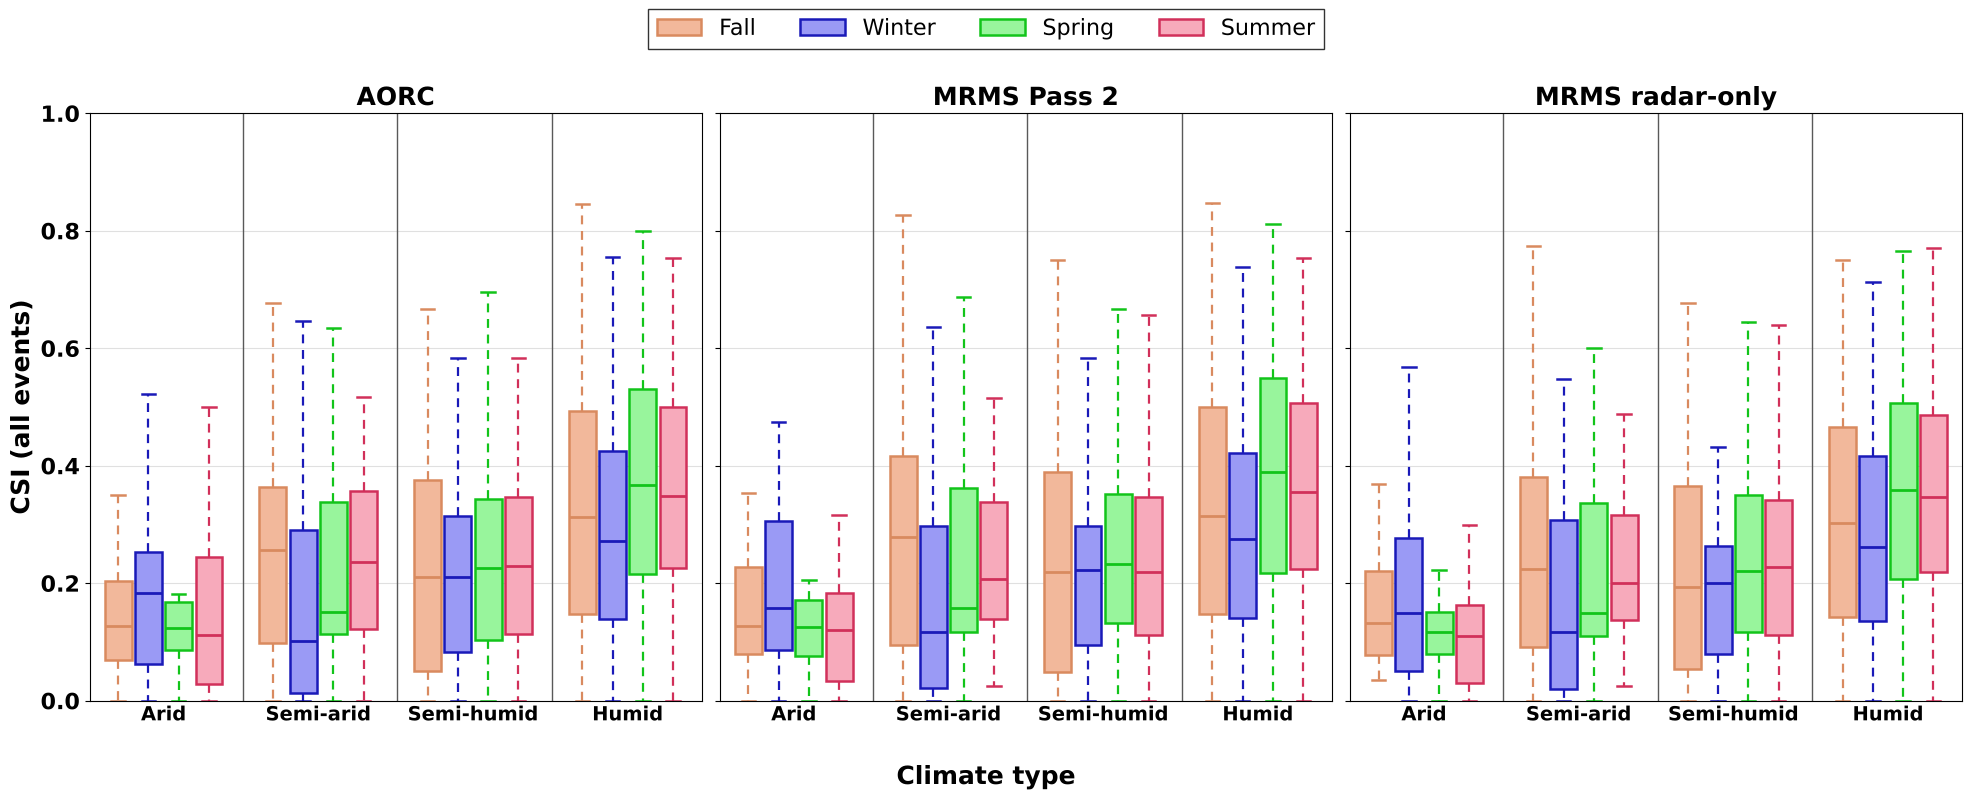

In [11]:
det = ctg[(ctg["period_type"] == "season") & (ctg["event_set"] == EVENT_SET)].rename(columns={"period": "season"})

fig = plots.figure_by_product(det, "CSI", f"CSI ({EVENT_SET} events)", whis=WHISKERS, ylim=(0, 1))
save(fig, f"CSI_by_climate_season_{EVENT_SET}")

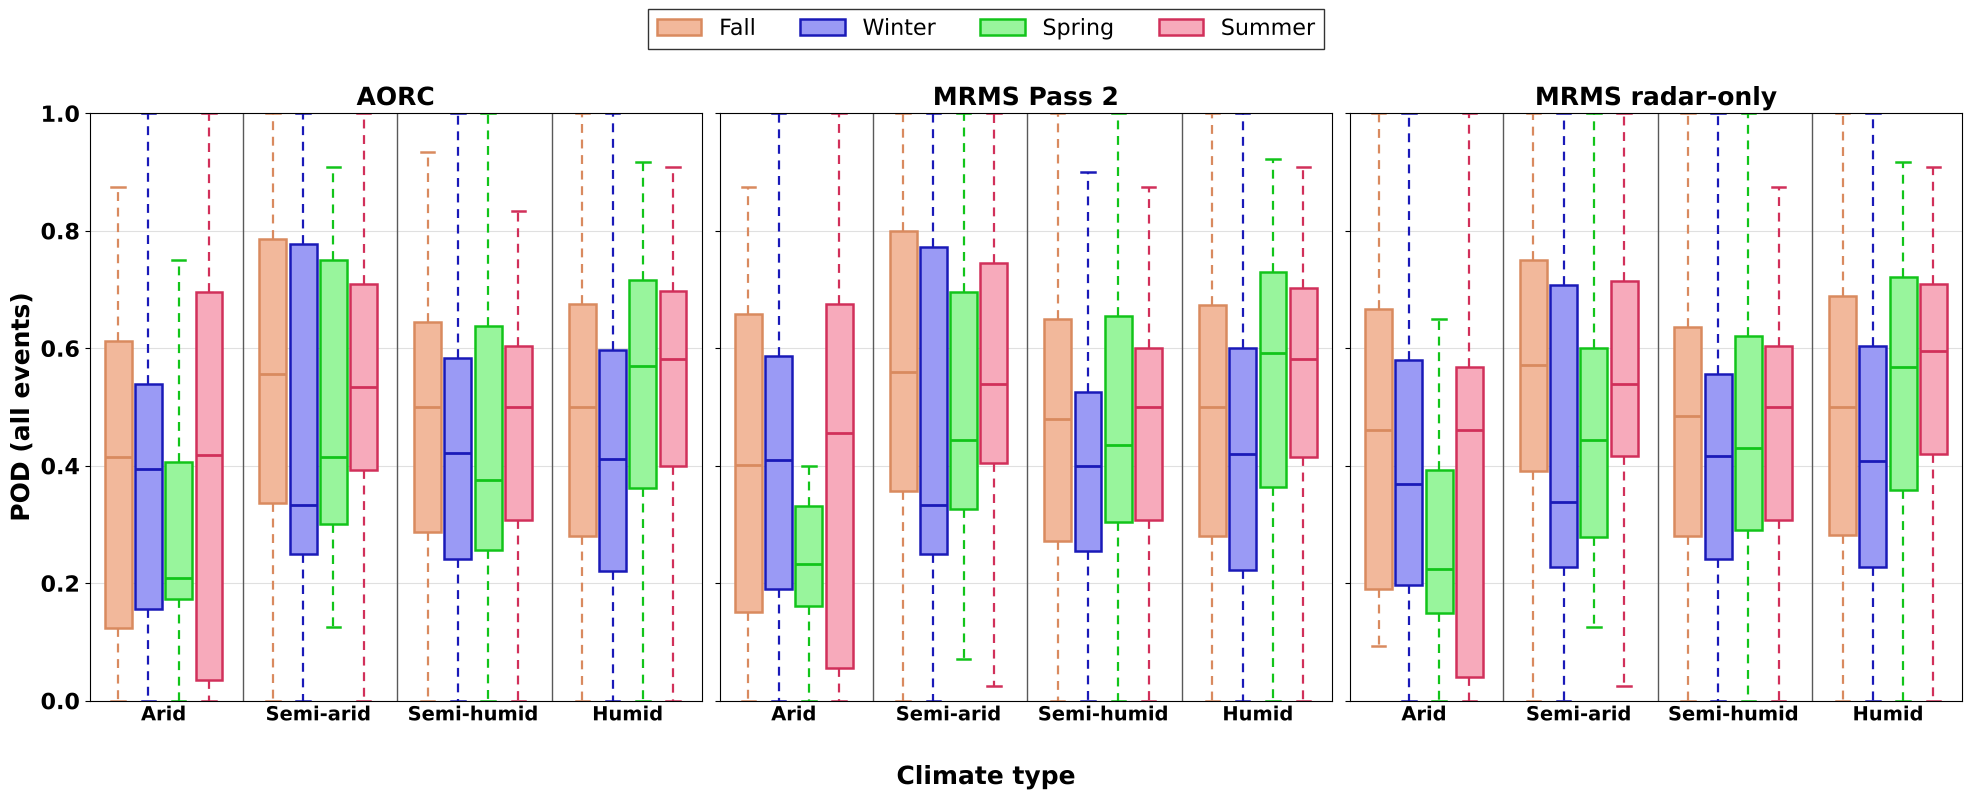

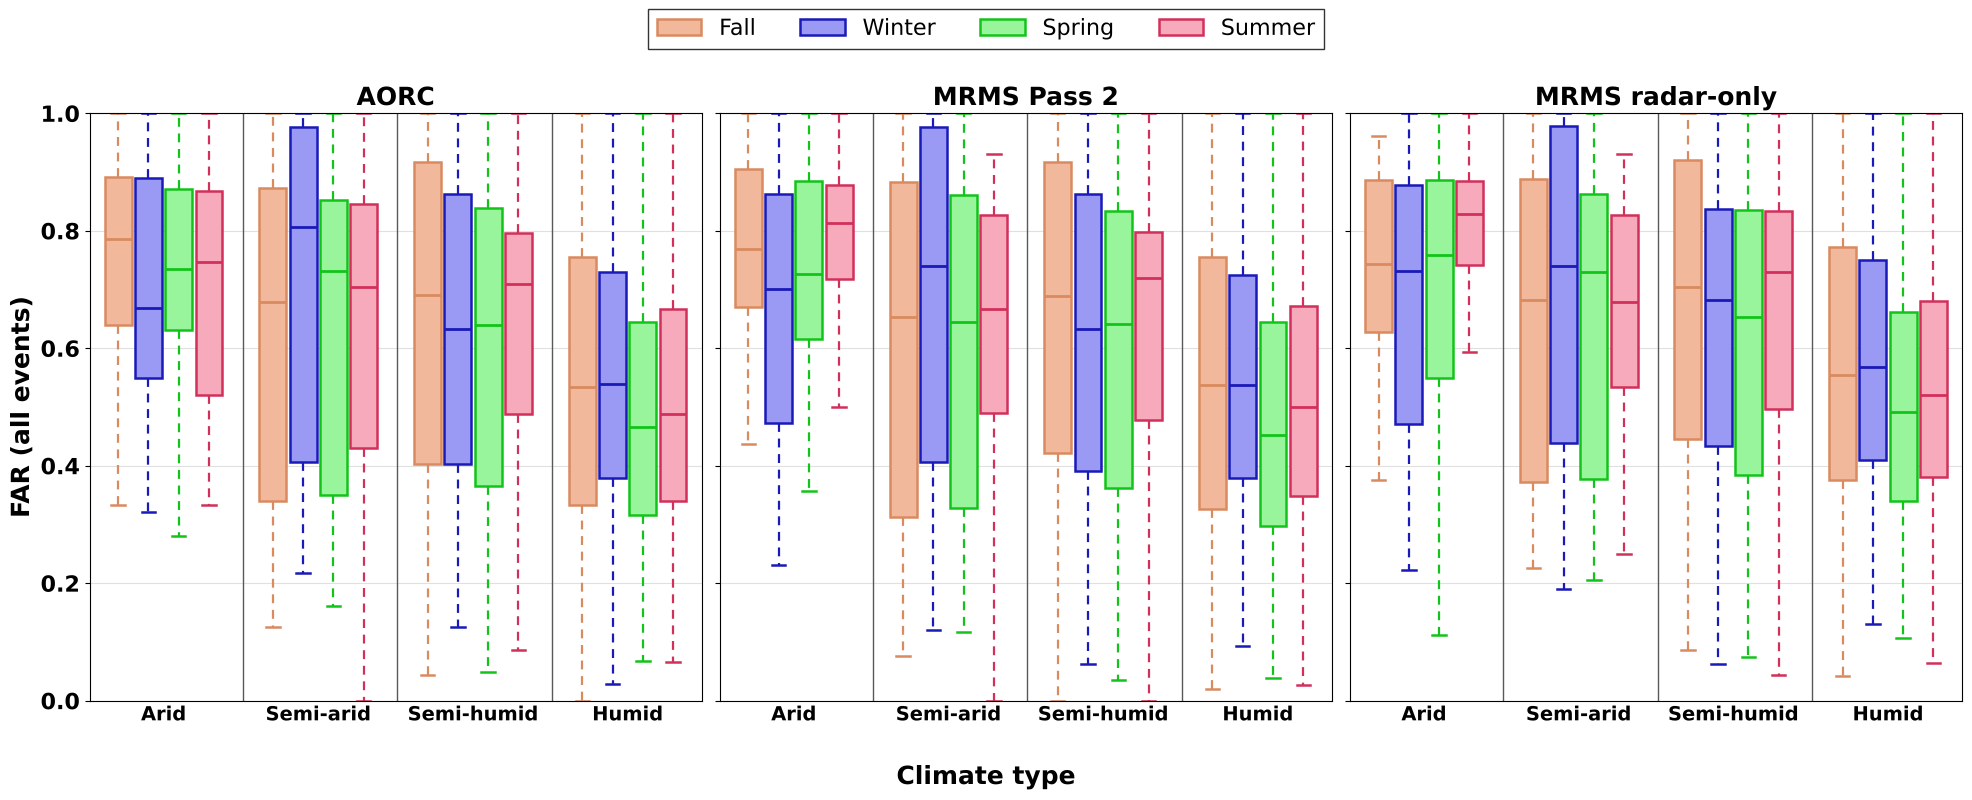

In [12]:
fig = plots.figure_by_product(det, "POD", f"POD ({EVENT_SET} events)", whis=WHISKERS, ylim=(0, 1))
save(fig, f"POD_by_climate_season_{EVENT_SET}")
fig = plots.figure_by_product(det, "FAR", f"FAR ({EVENT_SET} events)", whis=WHISKERS, ylim=(0, 1))
save(fig, f"FAR_by_climate_season_{EVENT_SET}")

## 4. Larger floods, pooled by climate type and season

For the larger floods (about 3 per year at each gage) the events of all gages of a climate type are pooled before the scores are computed, because one gage has too few of them per season.

hits                      misses                       \
season               Fall Winter Spring Summer   Fall Winter Spring Summer   
product aridity_zone                                                         
AORC    Arid           31     61     30     46     28     27     33     30   
        Humid         507   1265   1483   1008    457   1608   2255    769   
        Semi-arid      63     45     79     96     20     14     55     61   
        Semi-humid     63     49    127     95     27     23     98     90   
MRMS_P2 Arid           35     62     33     43     24     26     30     33   
        Humid         493   1218   1478   1052    471   1655   2260    725   
        Semi-arid      63     44     74    100     20     15     60     57   
        Semi-humid     63     47    129    106     27     25     96     79   
MRMS_RO Arid           35     52     23     41     24     36     40     35   
        Humid         435    949   1242   1057    529   1924   2496    720   
        Semi-arid      62     37     77     97     21     22     57     60   
        Semi-humid     63     46    130    106     27     26     95     79   

                     false_alarms                        CSI                \
season                       Fall Winter Spring Summer  Fall Winter Spring   
product aridity_zone                                                         
AORC    Arid                  247    222    275    299  0.10   0.20   0.09   
        Humid                4372   3847   5945   7471  0.10   0.19   0.15   
        Semi-arid             488    322    609    550  0.11   0.12   0.11   
        Semi-humid            546    299    644    552  0.10   0.13   0.15   
MRMS_P2 Arid                  279    227    271    388  0.10   0.20   0.10   
        Humid                4448   3848   5775   8363  0.09   0.18   0.16   
        Semi-arid             509    317    616    591  0.11   0.12   0.10   
        Semi-humid            568    303    659    579  0.10   0.13   0.15   
MRMS_RO Arid                  278    205    226    397  0.10   0.18   0.08   
        Humid                4486   4054   6412   9388  0.08   0.14   0.12   
        Semi-arid             535    324    663    659  0.10   0.10   0.10   
        Semi-humid            601    329    738    648  0.09   0.11   0.13   

                             
season               Summer  
product aridity_zone         
AORC    Arid           0.12  
        Humid          0.11  
        Semi-arid      0.14  
        Semi-humid     0.13  
MRMS_P2 Arid           0.09  
        Humid          0.10  
        Semi-arid      0.13  
        Semi-humid     0.14  
MRMS_RO Arid           0.09  
        Humid          0.09  
        Semi-arid      0.12  
        Semi-humid     0.13

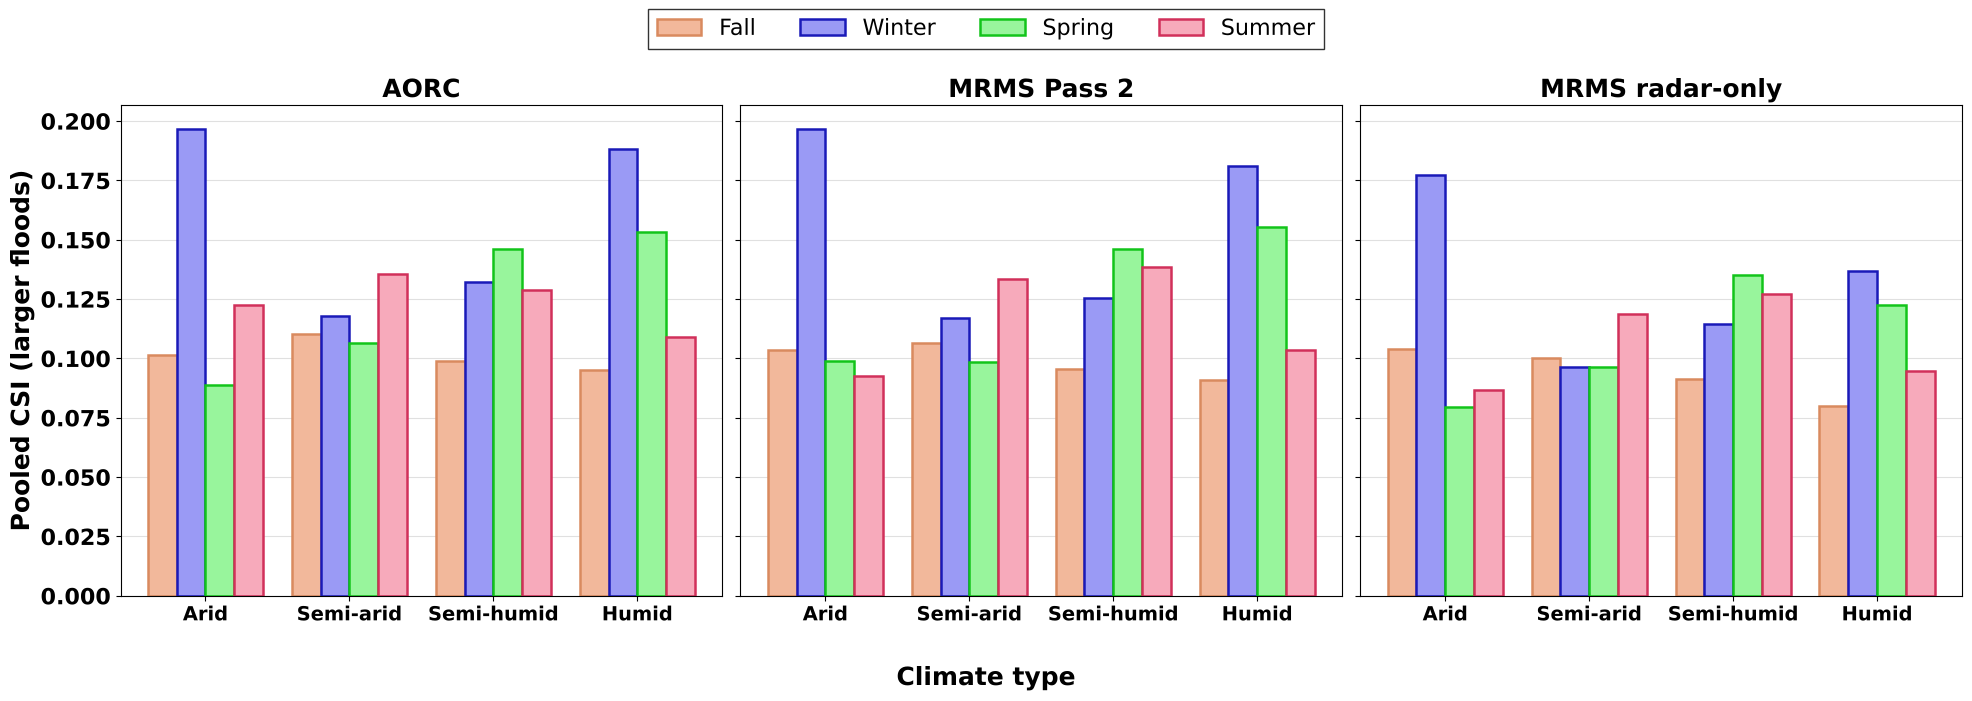

In [13]:
big = ctg[(ctg["period_type"] == "season") & (ctg["event_set"] == "larger")]
pool = big.groupby(["product", "aridity_zone", "period"])[["hits", "misses", "false_alarms"]].sum()
pool["POD"] = pool["hits"] / (pool["hits"] + pool["misses"])
pool["FAR"] = pool["false_alarms"] / (pool["hits"] + pool["false_alarms"])
pool["CSI"] = pool["hits"] / (pool["hits"] + pool["misses"] + pool["false_alarms"])
pool = pool.rename_axis(index={"period": "season"})
pool.round(3).to_csv(cfg.FIGURES / "pooled_detection_larger_by_climate_season.csv")

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)
x = np.arange(len(cfg.ZONES))
for ax, prod in zip(axes, cfg.PRODUCTS):
    for i, s in enumerate(cfg.SEASONS):
        v = [pool["CSI"].get((prod, z, s), np.nan) for z in cfg.ZONES]
        edge, face = plots.SEASON_COLORS[s]
        ax.bar(x + (i - 1.5) * 0.2, v, 0.2, color=face, edgecolor=edge, linewidth=1.8, label=s)
    ax.set_xticks(x)
    ax.set_xticklabels(cfg.ZONES, fontweight="bold", fontsize=14)
    ax.set_title(cfg.PRODUCT_LABEL[prod])
    ax.grid(axis="y", color="0.88")
    ax.set_axisbelow(True)
    for lab in ax.get_yticklabels():
        lab.set_fontweight("bold")
axes[0].set_ylabel("Pooled CSI (larger floods)")
fig.supxlabel("Climate type", fontweight="bold", fontsize=18)
plots.season_legend_top(fig)
save(fig, "CSI_pooled_larger_by_climate_season")
pool.unstack("season").reindex(columns=cfg.SEASONS, level=1)[["hits", "misses", "false_alarms", "CSI"]].round(2)

## 5. Event-based evaluation of the matched events

Each gage contributes the median over its matched events (hits) of a season.

### Peak magnitude

Peak ratio = simulated peak / observed peak, on a logarithmic axis: 1 = perfect, 4 = four times too high, 1/4 = four times too low.

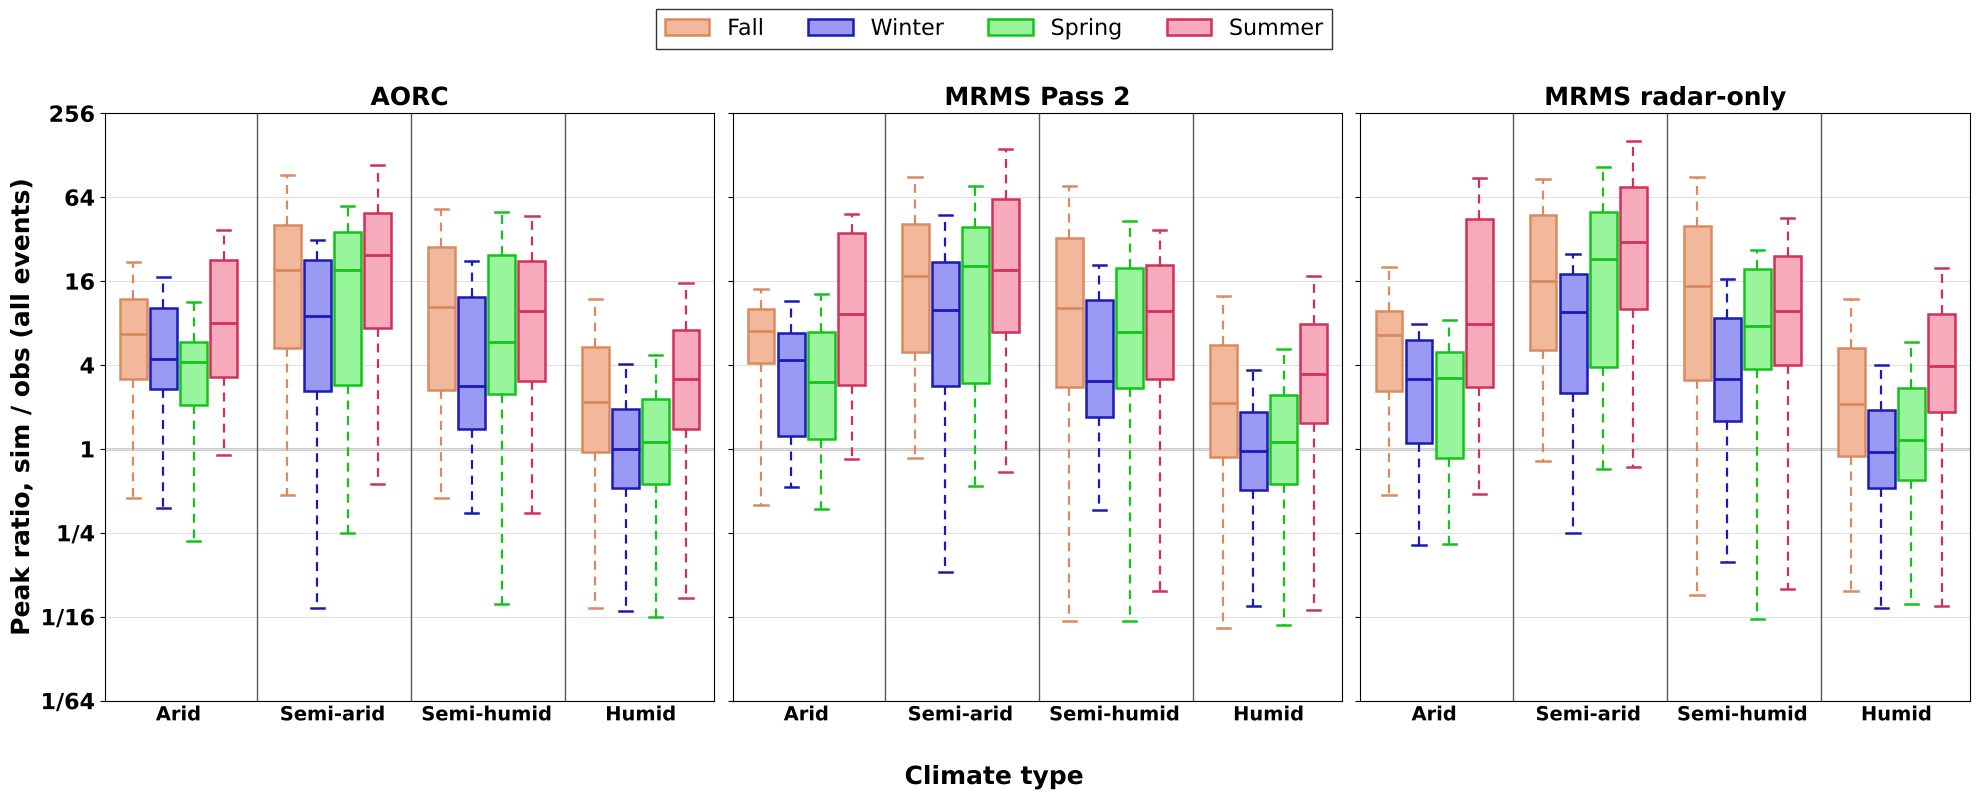

In [14]:
ev = ems[(ems["period_type"] == "season") & (ems["event_set"] == EVENT_SET)].rename(columns={"period": "season"})

fig = plots.figure_by_product(ev, "peak_ratio_median", f"Peak ratio, sim / obs ({EVENT_SET} events)", ref=1, whis=WHISKERS)
for ax in fig.axes:
    ax.set_yscale("log")
    ax.set_yticks([1 / 64, 1 / 16, 0.25, 1, 4, 16, 64, 256])
    ax.set_yticklabels(["1/64", "1/16", "1/4", "1", "4", "16", "64", "256"])
    ax.minorticks_off()
save(fig, f"peak_ratio_by_climate_season_{EVENT_SET}")

### Peak timing

Timing error = time of the simulated peak minus time of the observed peak. Negative = the simulated peak is early. The matching allows at most 12 h either way.

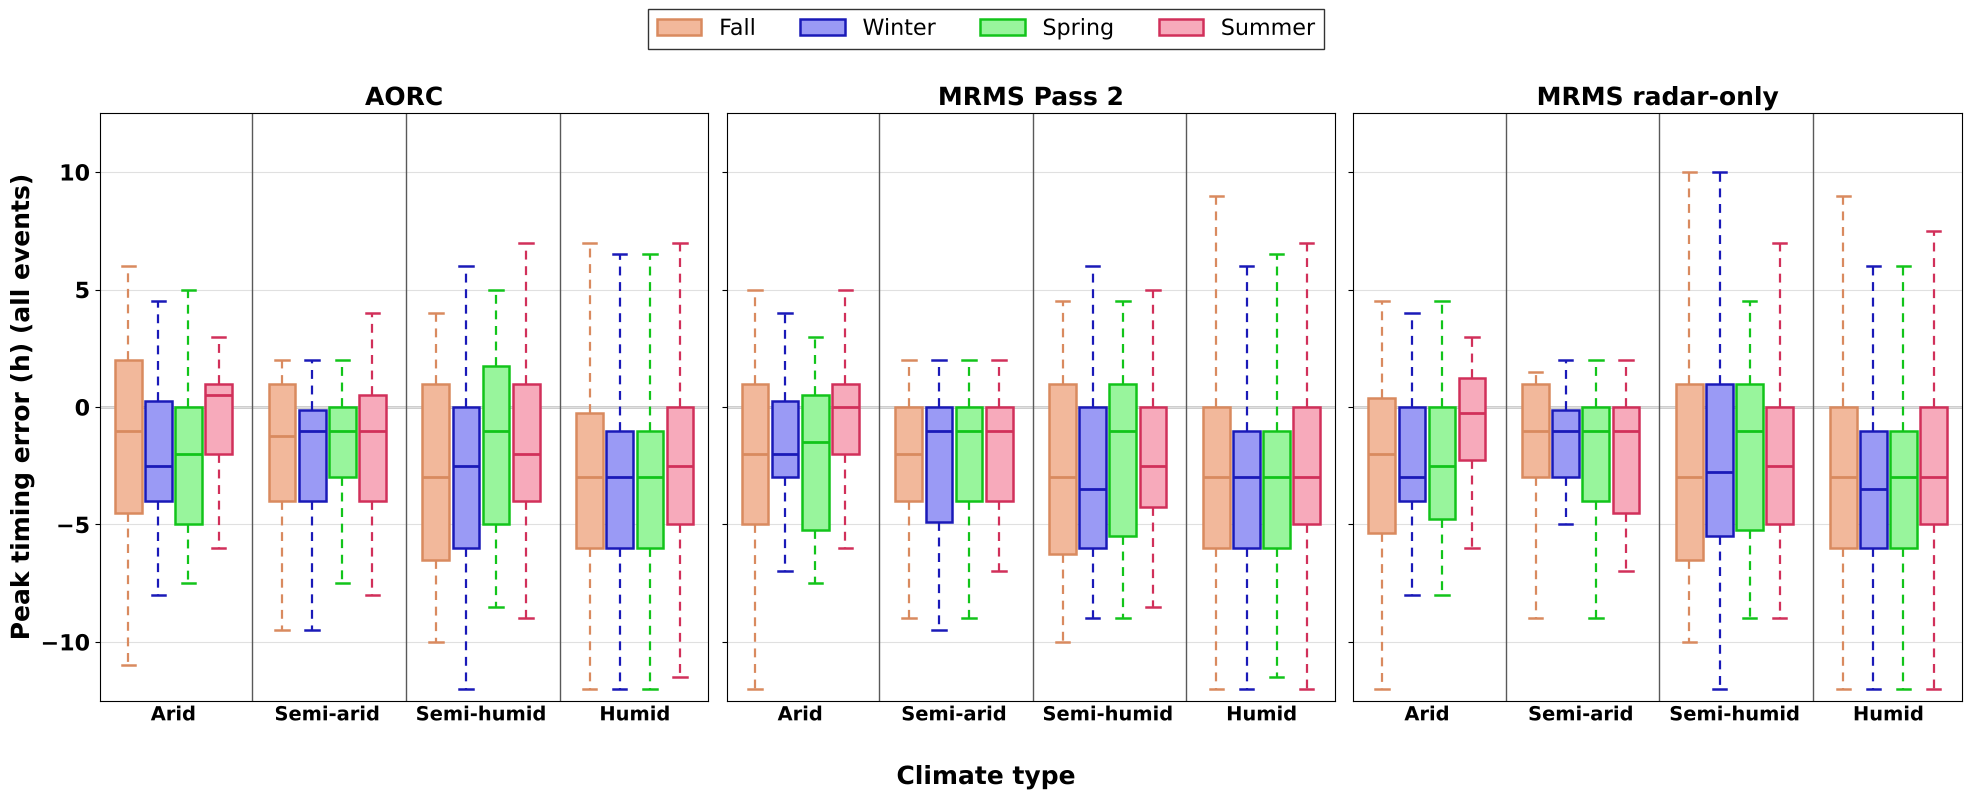

In [15]:
fig = plots.figure_by_product(ev, "time_to_peak_err_h_median", f"Peak timing error (h) ({EVENT_SET} events)",
                              ref=0, whis=WHISKERS, ylim=(-12.5, 12.5))
save(fig, f"peak_timing_by_climate_season_{EVENT_SET}")

### Time to peak (rise time)

Rise time = hours from the start of an event to its peak. Error = simulated minus observed rise time. Positive = the simulated flood rises more slowly.

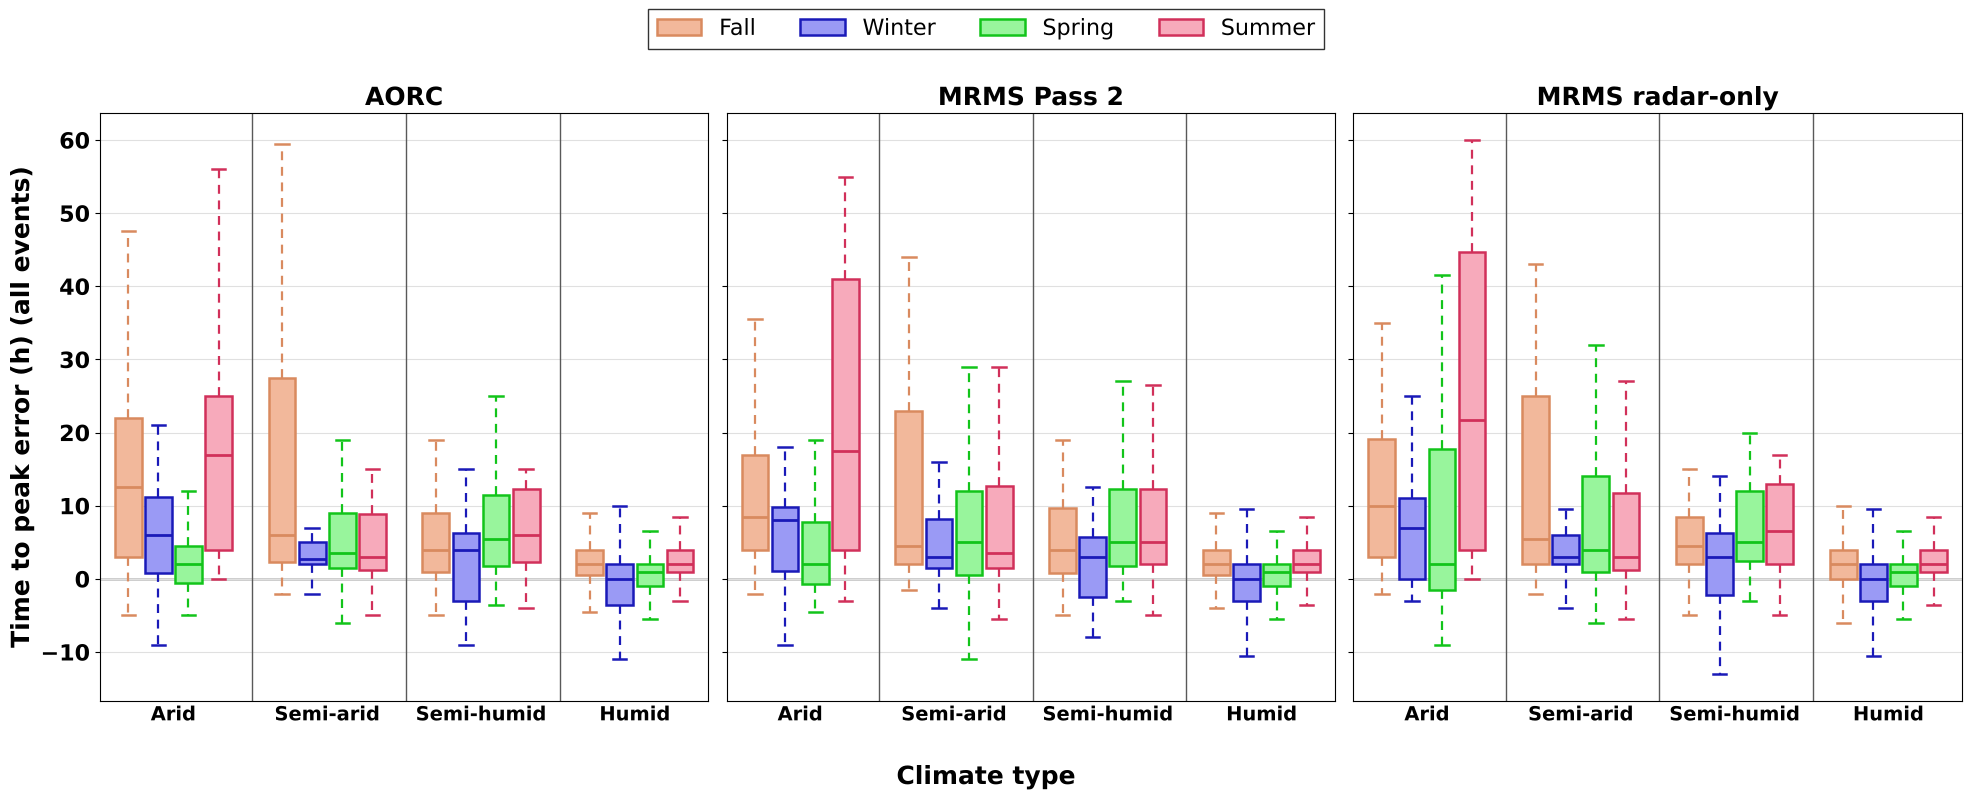

In [16]:
fig = plots.figure_by_product(ev, "rise_err_h_median", f"Time to peak error (h) ({EVENT_SET} events)", ref=0, whis=WHISKERS)
save(fig, f"time_to_peak_by_climate_season_{EVENT_SET}")

### Volume

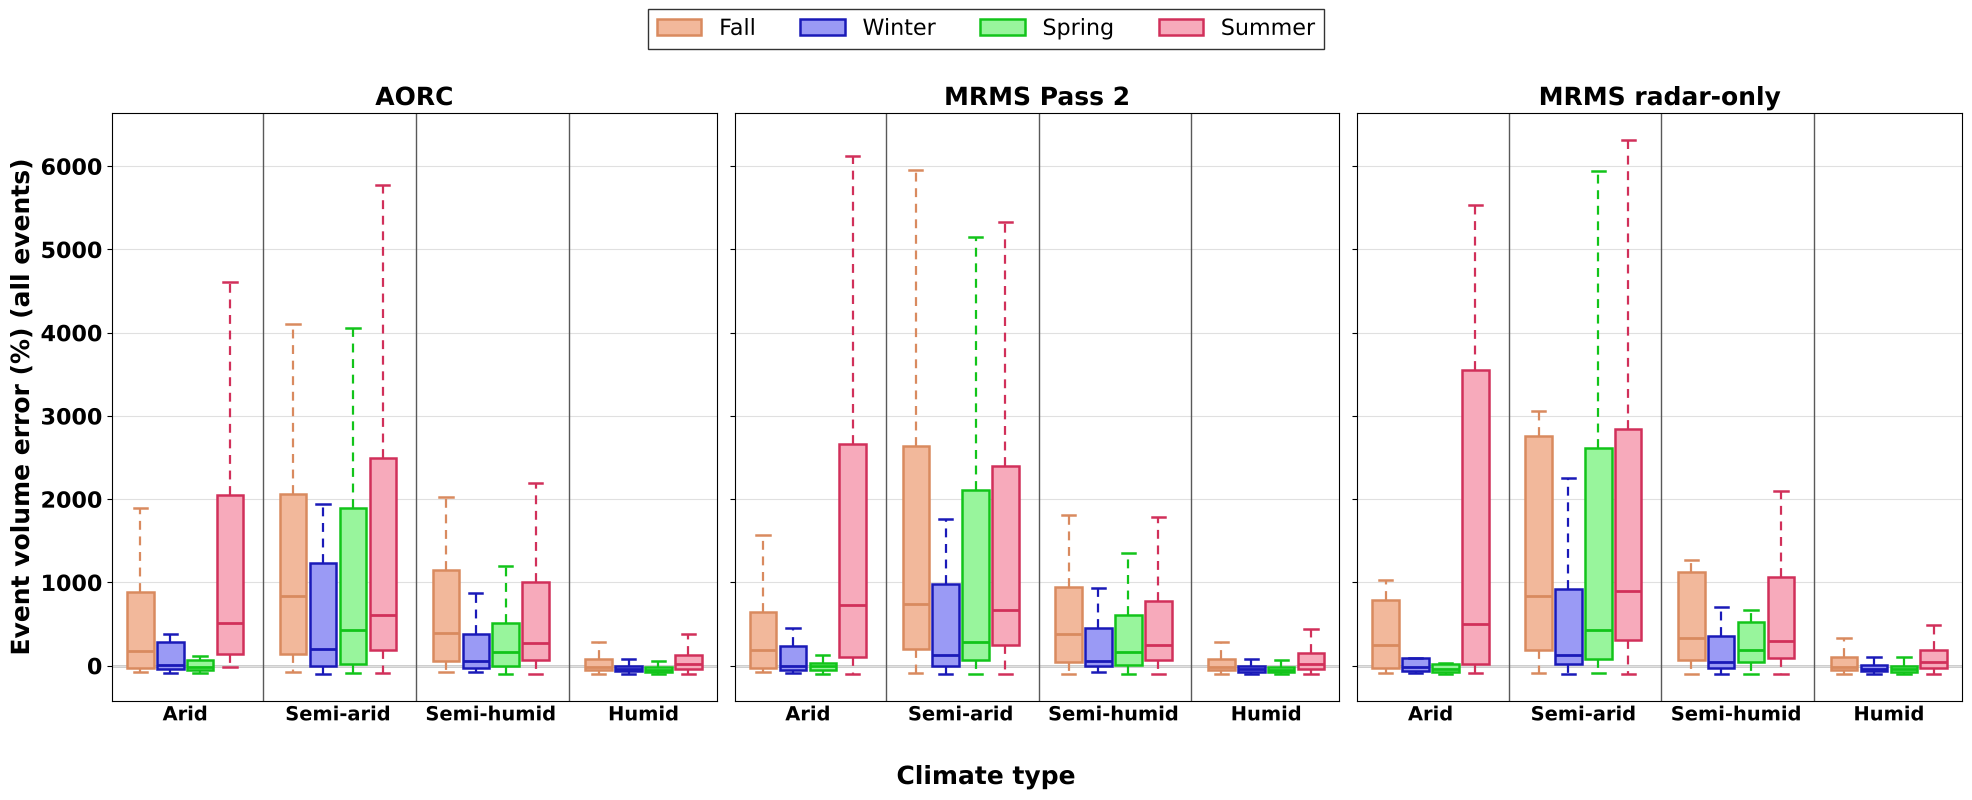

In [17]:
fig = plots.figure_by_product(ev, "vol_err_pct_median", f"Event volume error (%) ({EVENT_SET} events)", ref=0, whis=WHISKERS)
save(fig, f"volume_error_by_climate_season_{EVENT_SET}")

In [18]:
med_ev = (ev.groupby(["product", "aridity_zone", "season"])[["peak_ratio_median", "time_to_peak_err_h_median",
                                                              "rise_err_h_median", "vol_err_pct_median"]].median()
          .round(2).unstack("season").reindex(columns=cfg.SEASONS, level=1)
          .reindex(index=[(p, z) for p in cfg.PRODUCTS for z in cfg.ZONES]))
med_ev.to_csv(cfg.FIGURES / f"medians_events_by_climate_season_{EVENT_SET}.csv")
med_ev

peak_ratio_median                       \
season                            Fall Winter Spring Summer   
product aridity_zone                                          
AORC    Arid                      6.65   4.40   4.22   8.06   
        Semi-arid                19.23   9.00  19.36  24.66   
        Semi-humid               10.52   2.85   5.87   9.73   
        Humid                     2.17   1.00   1.12   3.18   
MRMS_P2 Arid                      7.05   4.34   3.02   9.23   
        Semi-arid                17.31   9.95  20.64  19.18   
        Semi-humid               10.29   3.05   6.89   9.76   
        Humid                     2.15   0.96   1.12   3.48   
MRMS_RO Arid                      6.59   3.17   3.25   7.82   
        Semi-arid                16.16   9.62  23.24  30.53   
        Semi-humid               14.86   3.16   7.57   9.79   
        Humid                     2.09   0.95   1.16   3.96   

                     time_to_peak_err_h_median                       \
season                                    Fall Winter Spring Summer   
product aridity_zone                                                  
AORC    Arid                             -1.00  -2.50   -2.0   0.50   
        Semi-arid                        -1.25  -1.00   -1.0  -1.00   
        Semi-humid                       -3.00  -2.50   -1.0  -2.00   
        Humid                            -3.00  -3.00   -3.0  -2.50   
MRMS_P2 Arid                             -2.00  -2.00   -1.5   0.00   
        Semi-arid                        -2.00  -1.00   -1.0  -1.00   
        Semi-humid                       -3.00  -3.50   -1.0  -2.50   
        Humid                            -3.00  -3.00   -3.0  -3.00   
MRMS_RO Arid                             -2.00  -3.00   -2.5  -0.25   
        Semi-arid                        -1.00  -1.00   -1.0  -1.00   
        Semi-humid                       -3.00  -2.75   -1.0  -2.50   
        Humid                            -3.00  -3.50   -3.0  -3.00   

                     rise_err_h_median                       \
season                            Fall Winter Spring Summer   
product aridity_zone                                          
AORC    Arid                      12.5   6.00    2.0  17.00   
        Semi-arid                  6.0   2.75    3.5   3.00   
        Semi-humid                 4.0   4.00    5.5   6.00   
        Humid                      2.0   0.00    1.0   2.00   
MRMS_P2 Arid                       8.5   8.00    2.0  17.50   
        Semi-arid                  4.5   3.00    5.0   3.50   
        Semi-humid                 4.0   3.00    5.0   5.00   
        Humid                      2.0   0.00    1.0   2.00   
MRMS_RO Arid                      10.0   7.00    2.0  21.75   
        Semi-arid                  5.5   3.00    4.0   3.00   
        Semi-humid                 4.5   3.00    5.0   6.50   
        Humid                      2.0   0.00    1.0   2.00   

                     vol_err_pct_median                          
season                             Fall  Winter  Spring  Summer  
product aridity_zone                                             
AORC    Arid                     176.26    6.20  -11.02  513.98  
        Semi-arid                838.42  199.06  427.42  607.08  
        Semi-humid               397.09   54.58  159.18  267.27  
        Humid                    -16.45  -39.65  -49.45   16.00  
MRMS_P2 Arid                     193.02   -3.90   -9.61  724.61  
        Semi-arid                737.24  130.35  285.73  666.02  
        Semi-humid               381.75   51.68  160.09  253.22  
        Humid                    -19.16  -43.87  -51.77   24.87  
MRMS_RO Arid                     247.59  -19.26  -36.08  496.23  
        Semi-arid                833.04  125.87  423.38  903.03  
        Semi-humid               338.56   43.99  188.21  294.97  
        Humid                    -15.71  -35.05  -43.49   46.14

## Going further

The same tables answer other splits without rerunning anything:

- by basin size: group by `area_class` instead of `aridity_zone`
- by year: `period_type == "water_year"` or `"season_year"` in `continuous_metrics`
- by month: `period_type == "month"`
- single events: `event_metrics` has one row per matched flood with its season, water year and climate type